# Laboratorio 1: Evidencia de sparse data y Ley de Zipf

Estudiante: Cristian Bastidas

Corpus analizado: Moby Dick (Herman Melville, 1851), tomado de la colección Gutenberg incluida en NLTK (archivo melville-moby_dick.txt).

Se sigue la misma secuencia de la guía de Tom Sawyer: corpus, preprocesamiento, tokens y tipos, frecuencias, hapax, ranking, gráfica log-log y análisis de Zipf.

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

nltk.download("gutenberg", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.corpus import gutenberg

[nltk_data] Error loading gutenberg: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to 

## 1. Carga del corpus

La versión de NLTK ya viene sin el encabezado ni la licencia de Project Gutenberg. Solo queda una línea inicial agregada por NLTK con el título y el año, que se elimina porque no es parte del texto de Melville.

In [2]:
texto_crudo = gutenberg.raw("melville-moby_dick.txt")
print(texto_crudo[:200])
print("Caracteres:", len(texto_crudo))

[Moby Dick by Herman Melville 1851]


ETYMOLOGY.

(Supplied by a Late Consumptive Usher to a Grammar School)

The pale Usher--threadbare in coat, heart, body, and brain; I see him
now.  He was
Caracteres: 1242990


In [3]:
texto = re.sub(r"^\[.*?\]\s*", "", texto_crudo, count=1)

for marca in ["Project Gutenberg", "START OF", "END OF", "License"]:
    print(marca, "->", marca in texto)

Project Gutenberg -> False
START OF -> False
END OF -> False
License -> False


## 2. Preprocesamiento

Decisiones tomadas:

1. Todo el texto se pasa a minúsculas, para que "Whale" y "whale" cuenten como un mismo tipo.
2. Se toman como token solo las palabras formadas por letras. Se descartan números, signos de puntuación y símbolos.
3. El doble guion "--", que Melville usa como raya, se reemplaza por un espacio para que no pegue palabras.
4. Las contracciones con apóstrofo (por ejemplo "don't", "whale's") y las palabras compuestas con guion simple (por ejemplo "sperm-whale") se mantienen como un solo token, porque así aparecen escritas en la obra.
5. El guion bajo, que en esta edición marca la cursiva, se elimina.

In [4]:
def preprocesar(t, minusculas=True, separar_guiones=False):
    t = t.replace("_", " ").replace("--", " ")
    if minusculas:
        t = t.lower()
    if separar_guiones:
        return re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)*", t)
    return re.findall(r"[A-Za-z]+(?:['-][A-Za-z]+)*", t)

tokens = preprocesar(texto)
print(tokens[:30])

['etymology', 'supplied', 'by', 'a', 'late', 'consumptive', 'usher', 'to', 'a', 'grammar', 'school', 'the', 'pale', 'usher', 'threadbare', 'in', 'coat', 'heart', 'body', 'and', 'brain', 'i', 'see', 'him', 'now', 'he', 'was', 'ever', 'dusting', 'his']


## 3. Tokens, tipos y TTR

In [5]:
frecuencias = Counter(tokens)
n_tokens = len(tokens)
n_tipos = len(frecuencias)
ttr = n_tipos / n_tokens

print(f"Número de tokens: {n_tokens:,}")
print(f"Número de tipos:  {n_tipos:,}")
print(f"TTR: {ttr:.4f} ({ttr*100:.2f} %)")

Número de tokens: 213,407
Número de tipos:  18,623
TTR: 0.0873 (8.73 %)


## 4. Frecuencias y ranking

In [6]:
ranking = pd.DataFrame(frecuencias.most_common(), columns=["palabra", "frecuencia"])
ranking.index = ranking.index + 1
ranking.index.name = "rango"
ranking["r_x_f"] = ranking.index * ranking["frecuencia"]
ranking.head(30)

,palabra,frecuencia,r_x_f
rango,,,
1,the,14428,14428
2,of,6586,13172
3,and,6416,19248
4,a,4711,18844
5,to,4597,22985
6,in,4164,24984
7,that,2990,20930
8,his,2530,20240
9,it,2420,21780


In [7]:
cobertura_top100 = ranking["frecuencia"].head(100).sum() / n_tokens
print(f"Tokens cubiertos por los 100 tipos más frecuentes: {ranking['frecuencia'].head(100).sum():,}")
print(f"Cobertura Top 100: {cobertura_top100*100:.2f} %")

Tokens cubiertos por los 100 tipos más frecuentes: 108,738
Cobertura Top 100: 50.95 %


## 5. Hapax legomena y tipos de baja frecuencia

In [8]:
hapax = [p for p, f in frecuencias.items() if f == 1]
n_hapax = len(hapax)
pct_hapax = n_hapax / n_tipos
n_bajos = sum(1 for f in frecuencias.values() if f <= 10)
pct_bajos = n_bajos / n_tipos

print(f"Hapax legomena: {n_hapax:,}")
print(f"Porcentaje de hapax sobre los tipos: {pct_hapax*100:.2f} %")
print(f"Porcentaje de hapax sobre los tokens: {n_hapax/n_tokens*100:.2f} %")
print(f"Tipos con frecuencia <= 10: {n_bajos:,} ({pct_bajos*100:.2f} %)")
print("Ejemplos de hapax:", sorted(hapax)[1000:1015])

Hapax legomena: 8,856
Porcentaje de hapax sobre los tipos: 47.55 %
Porcentaje de hapax sobre los tokens: 4.15 %
Tipos con frecuencia <= 10: 16,688 (89.61 %)
Ejemplos de hapax: ['bunk', 'bunks', 'bunting', 'bunyan', 'buoyantly', 'buoys', 'burgher', 'burghers', 'burglaries', 'buried-alive', 'buries', "burke's", 'burkes', 'burly', 'burly-browed']


In [9]:
tabla_f = pd.Series(Counter(frecuencias.values())).sort_index()
tabla_bajas = pd.DataFrame({
    "frecuencia": list(range(1, 11)),
    "tipos": [tabla_f.get(i, 0) for i in range(1, 11)],
})
tabla_bajas["% de tipos"] = (tabla_bajas["tipos"] / n_tipos * 100).round(2)
tabla_bajas["% acumulado"] = tabla_bajas["% de tipos"].cumsum().round(2)
tabla_bajas

,frecuencia,tipos,% de tipos,% acumulado
0,1,8856,47.55,47.55
1,2,3061,16.44,63.99
2,3,1661,8.92,72.91
3,4,912,4.90,77.81
4,5,651,3.50,81.31
5,6,476,2.56,83.87
6,7,342,1.84,85.71
7,8,310,1.66,87.37
8,9,239,1.28,88.65
9,10,180,0.97,89.62


## 6. Gráfica log-log y ajuste lineal

In [10]:
rangos = ranking.index.values.astype(float)
frec = ranking["frecuencia"].values.astype(float)
log_r = np.log10(rangos)
log_f = np.log10(frec)

pendiente, intercepto = np.polyfit(log_r, log_f, 1)
pred = pendiente * log_r + intercepto
r2 = 1 - np.sum((log_f - pred) ** 2) / np.sum((log_f - log_f.mean()) ** 2)
print(f"Pendiente (todos los rangos): {pendiente:.4f}")
print(f"Intercepto: {intercepto:.4f}  ->  C aproximado = {10**intercepto:,.0f}")
print(f"R2 del ajuste: {r2:.4f}")

Pendiente (todos los rangos): -1.1226
Intercepto: 4.6773  ->  C aproximado = 47,570
R2 del ajuste: 0.9781


In [11]:
m = (rangos >= 10) & (rangos <= 1000)
pend_media, int_media = np.polyfit(log_r[m], log_f[m], 1)
print(f"Pendiente en rangos 10 a 1000: {pend_media:.4f}")

m2 = frec > 1
pend_sin_hapax, _ = np.polyfit(log_r[m2], log_f[m2], 1)
print(f"Pendiente sin hapax: {pend_sin_hapax:.4f}")

Pendiente en rangos 10 a 1000: -1.0947
Pendiente sin hapax: -1.0886


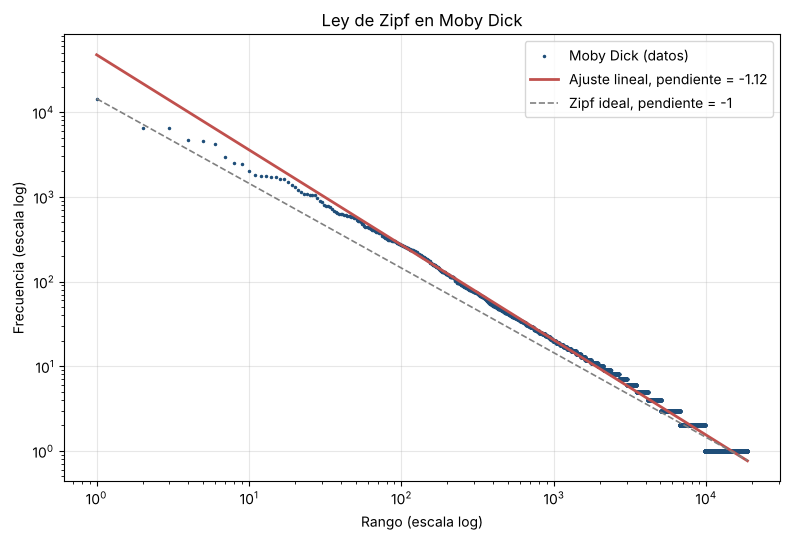

In [12]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.loglog(rangos, frec, ".", markersize=3, color="#1f4e79", label="Moby Dick (datos)")
ax.loglog(rangos, 10**pred, "-", color="#c0504d", linewidth=2,
          label=f"Ajuste lineal, pendiente = {pendiente:.2f}")
ax.loglog(rangos, frec[0] / rangos, "--", color="gray", linewidth=1.2,
          label="Zipf ideal, pendiente = -1")
ax.set_xlabel("Rango (escala log)")
ax.set_ylabel("Frecuencia (escala log)")
ax.set_title("Ley de Zipf en Moby Dick")
ax.grid(True, which="major", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("zipf_moby_dick.png", dpi=200)
plt.show()

In [13]:
ranking.loc[[1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]]

,palabra,frecuencia,r_x_f
rango,,,
1,the,14428,14428
2,of,6586,13172
3,and,6416,19248
5,to,4597,22985
10,i,1993,19930
20,at,1318,26360
50,upon,565,28250
100,thou,269,26900
200,line,122,24400


## 7. Efecto del preprocesamiento

Se repite el cálculo con otras decisiones de tokenización y normalización para ver cómo cambian los tipos, los hapax y la pendiente.

In [14]:
def indicadores(toks):
    fr = Counter(toks)
    nt, nv = len(toks), len(fr)
    f = np.array(sorted(fr.values(), reverse=True), dtype=float)
    r = np.arange(1, len(f) + 1)
    p, _ = np.polyfit(np.log10(r), np.log10(f), 1)
    return {
        "tokens": nt,
        "tipos": nv,
        "TTR": round(nv / nt, 4),
        "Top100 %": round(f[:100].sum() / nt * 100, 2),
        "hapax": int((f == 1).sum()),
        "hapax %": round((f == 1).sum() / nv * 100, 2),
        "freq<=10 %": round((f <= 10).sum() / nv * 100, 2),
        "pendiente": round(p, 4),
    }

texto_sin_raya = texto.replace("_", " ")
variantes = {
    "A. Base (minúsculas, compuestos unidos)": preprocesar(texto),
    "B. Sin pasar a minúsculas": preprocesar(texto, minusculas=False),
    "C. Separando palabras con guion": preprocesar(texto, separar_guiones=True),
    "D. word_tokenize de NLTK con puntuación": [t.lower() for t in nltk.word_tokenize(texto_sin_raya)],
}
tabla_prep = pd.DataFrame({k: indicadores(v) for k, v in variantes.items()}).T
tabla_prep

,tokens,tipos,TTR,Top100 %,hapax,hapax %,freq<=10 %,pendiente
"A. Base (minúsculas, compuestos unidos)",213407.0,18623.0,0.0873,50.95,8856.0,47.55,89.61,-1.1226
B. Sin pasar a minúsculas,213407.0,20682.0,0.0969,48.53,10318.0,49.89,90.43,-1.0965
C. Separando palabras con guion,215959.0,17362.0,0.0804,50.66,7665.0,44.15,88.40,-1.1540
D. word_tokenize de NLTK con puntuación,255400.0,18522.0,0.0725,57.81,8833.0,47.69,89.56,-1.1364


## 8. Tamaño del corpus y sparse data

Se calculan los indicadores sobre porciones crecientes del mismo texto. Así se ve qué pasa con el vocabulario y con los hapax cuando el corpus crece. La fila de 71,370 tokens usa una porción del mismo tamaño que Tom Sawyer (unos 71 000 tokens) para comparar en igualdad de tamaño.

In [15]:
cortes = [25000, 50000, 71370, 100000, 150000, n_tokens]
tabla_tam = pd.DataFrame({f"{c:,} tokens": indicadores(tokens[:c]) for c in cortes}).T
tabla_tam

,tokens,tipos,TTR,Top100 %,hapax,hapax %,freq<=10 %,pendiente
"25,000 tokens",25000.0,5177.0,0.2071,52.48,3218.0,62.16,94.71,-0.8855
"50,000 tokens",50000.0,7993.0,0.1599,52.00,4692.0,58.70,93.66,-0.9598
"71,370 tokens",71370.0,10169.0,0.1425,51.45,5709.0,56.14,93.17,-0.9881
"100,000 tokens",100000.0,12416.0,0.1242,51.31,6688.0,53.87,92.60,-1.0254
"150,000 tokens",150000.0,15449.0,0.1030,51.36,7709.0,49.90,91.11,-1.0755
"213,407 tokens",213407.0,18623.0,0.0873,50.95,8856.0,47.55,89.61,-1.1226


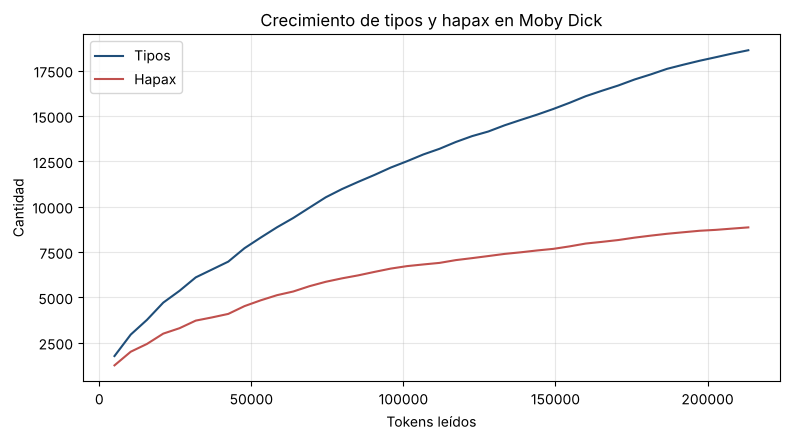

In [16]:
pasos = np.linspace(5000, n_tokens, 40).astype(int)
crec = []
for c in pasos:
    fr = Counter(tokens[:c])
    crec.append((c, len(fr), sum(1 for v in fr.values() if v == 1)))
crec = pd.DataFrame(crec, columns=["tokens", "tipos", "hapax"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(crec["tokens"], crec["tipos"], label="Tipos", color="#1f4e79")
ax.plot(crec["tokens"], crec["hapax"], label="Hapax", color="#c0504d")
ax.set_xlabel("Tokens leídos")
ax.set_ylabel("Cantidad")
ax.set_title("Crecimiento de tipos y hapax en Moby Dick")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("crecimiento_moby_dick.png", dpi=200)
plt.show()

## 9. Tabla comparativa con Tom Sawyer

In [17]:
comparacion = pd.DataFrame({
    "Tom Sawyer": ["~71,000", "~8,000", "~0.11", "~50.9 %", "~49.8 %", "> 90 %", "~ -1.0"],
    "Moby Dick": [f"{n_tokens:,}", f"{n_tipos:,}", f"{ttr:.3f}", f"{cobertura_top100*100:.1f} %",
                  f"{pct_hapax*100:.1f} %", f"{pct_bajos*100:.1f} %", f"{pendiente:.2f}"],
}, index=["Tokens", "Tipos", "TTR", "Cobertura Top 100", "Hapax legomena (%)",
          "% Tipos con freq <= 10", "Pendiente log-log"])
comparacion

,Tom Sawyer,Moby Dick
Tokens,"~71,000","213,407"
Tipos,"~8,000","18,623"
TTR,~0.11,0.087
Cobertura Top 100,~50.9 %,51.0 %
Hapax legomena (%),~49.8 %,47.6 %
% Tipos con freq <= 10,> 90 %,89.6 %
Pendiente log-log,~ -1.0,-1.12


In [18]:
import json
resumen = {
    "tokens": n_tokens, "tipos": n_tipos, "ttr": ttr, "top100": cobertura_top100,
    "hapax": n_hapax, "pct_hapax": pct_hapax, "bajos": n_bajos, "pct_bajos": pct_bajos,
    "pendiente": pendiente, "intercepto": intercepto, "r2": r2,
    "pend_media": pend_media, "pend_sin_hapax": pend_sin_hapax,
    "top20": ranking.head(20)[["palabra", "frecuencia"]].values.tolist(),
    "tabla_bajas": tabla_bajas.values.tolist(),
    "prep": tabla_prep.reset_index().values.tolist(),
    "tam": tabla_tam.reset_index().values.tolist(),
    "rxf": ranking.loc[[1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]].reset_index().values.tolist(),
}
with open("resumen_resultados.json", "w", encoding="utf-8") as fh:
    json.dump(resumen, fh, ensure_ascii=False, indent=1, default=str)
print("Listo")

Listo
